# Paradoxen en extremen in Belgische verkeersongevallen
2024 is het vergelijkingsjaar. Aantallen zijn geen individuele kans: verkeersvolume, wagenpark en gereden kilometers ontbreken. Kaart, slachtoffer- en voertuigbron hebben geen gedeeld ongeval-ID.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
B=Path.cwd()
if not (B/'figures').exists(): B=B/'analysis_notebooks'
G=B.parent/'data/gold';F=B/'figures';T=B/'tables'
load=lambda name:pd.read_parquet(G/name/(name+'.parquet'))
a,v,cars,geo=[load(x) for x in ['road_accidents','road_casualties','vehicle_collisions','accident_map']]
def chart(s,title,xlabel,file):
 fig,ax=plt.subplots(figsize=(10,5));s.sort_values().plot.barh(ax=ax,color='#175A78');ax.set(title=title,xlabel=xlabel,ylabel='');fig.tight_layout();fig.savefig(F/(file+'.png'),dpi=200,bbox_inches='tight');fig.savefig(F/(file+'.svg'),bbox_inches='tight');plt.show();plt.close(fig)


## 1. Welke wegtypen hebben de meeste registraties?
De kaartbron onderscheidt autosnelweg, gewestweg en gemeenteweg. De algemene ongevalstabel voegt de laatste twee samen. Daarom gebruiken we alleen de kaartbron voor deze ranglijst.

,registraties
CD_ROAD_TYPE_NL,
Gemeenteweg,16704
Gewestweg,16368
Autosnelweg,2715
onbekend,129


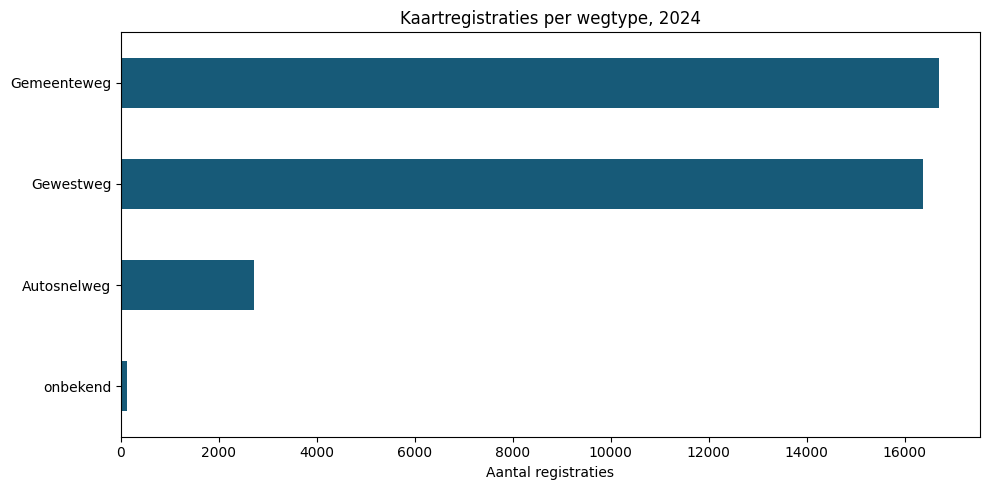

In [2]:
road=geo[geo.analysis_year==2024].groupby('CD_ROAD_TYPE_NL').size().rename('registraties').sort_values(ascending=False)
assert road.sum()==len(geo[geo.analysis_year==2024])
road.to_csv(T/'wegtype_kaart_2024.csv');display(road.to_frame())
chart(road,'Kaartregistraties per wegtype, 2024','Aantal registraties','11_wegtype_aantallen')


## 2. Volume tegenover ernst: een mogelijke paradox
Het percentage is ernstig gewond of overleden onder geregistreerde gewonden en doden op dat wegtype. Dit is geen ongevalskans per rit.

,letsel,ernstig,ernst_pct
TX_ROAD_TYPE_DESCR_NL,,,
Autosnelweg,3947,294,7.45
Gemeenteweg,19573,1596,8.15
Gewestweg,20622,1568,7.6
Onbekend,148,10,6.76


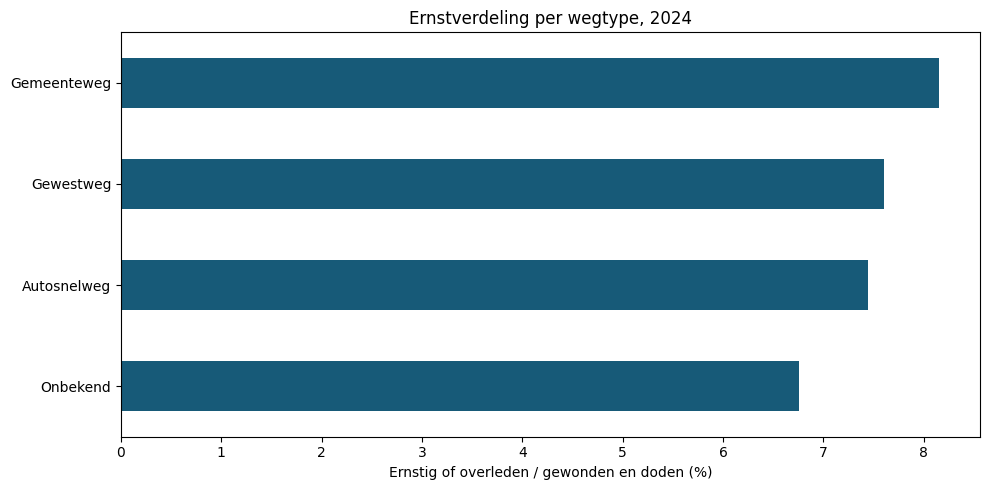

In [3]:
w=v[v.analysis_year==2024].copy();w['letsel']=w.MS_SLY_INJ+w.MS_SERLY_INJ+w.MS_DEAD_30_DAYS;w['ernstig']=w.MS_SERLY_INJ+w.MS_DEAD_30_DAYS
severity=w.groupby('TX_ROAD_TYPE_DESCR_NL')[['letsel','ernstig']].sum();severity['ernst_pct']=100*severity.ernstig/severity.letsel
severity.to_csv(T/'wegtype_ernst_2024.csv');display(severity.round(2))
chart(severity.ernst_pct,'Ernstverdeling per wegtype, 2024','Ernstig of overleden / gewonden en doden (%)','12_wegtype_ernst')


## 3. Welk voertuigtype valt op?
De voertuigbron beschrijft de klasse van het ongeval waarbij een voertuig betrokken was. Eén ongeval kan meerdere voertuigen leveren. Deze verhouding is geen kans op een ongeval per voertuig en zegt niets over schuld.

,voertuigen,ernstige_betrokkenheid,ernst_pct
segment,,,
sedans,4213,257,6.1
Stadswagens,9256,612,6.61
SUV,7361,526,7.15
Compacte auto's,5790,416,7.18
Monovolumes (klein en groot) en ludospace,2922,219,7.49
"Pick-up, bestelwagen, bestelwagen of bedrijfswagen",4899,393,8.02
Sportwagens,283,26,9.19
Onbekend,862,93,10.79
Motoren en bromfietsen,6390,705,11.03


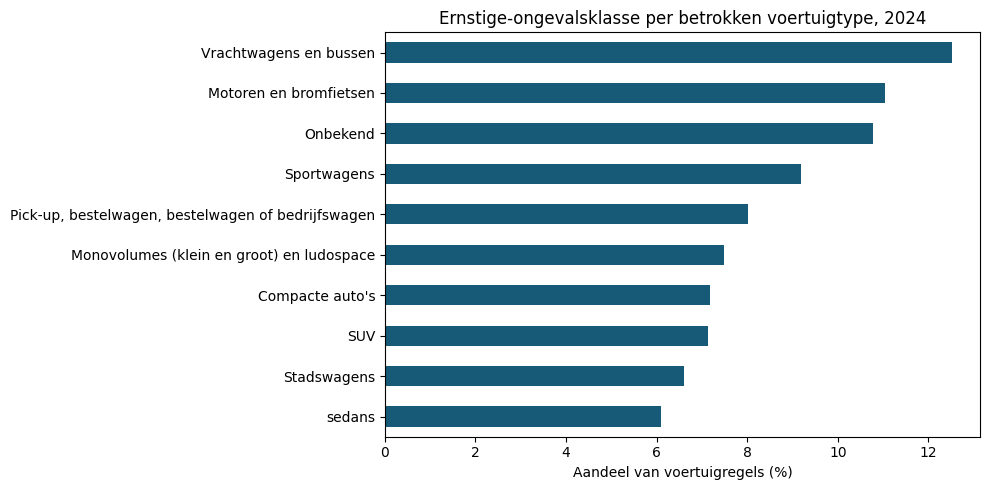

In [4]:
d=cars[cars.analysis_year==2024].copy();d['ernstig']=d.CD_ACCIDENT_CLASS.isin(['1','2','4']);d['segment']=d.TX_VEHICLE_SEGMENT_B_NL.fillna('Onbekend')
veh=d.groupby('segment').agg(voertuigen=('FL_VEHICLE','sum'),ernstige_betrokkenheid=('ernstig','sum'));veh['ernst_pct']=100*veh.ernstige_betrokkenheid/veh.voertuigen
veh=veh[veh.voertuigen>=100].sort_values('ernst_pct');veh.to_csv(T/'voertuigtype_ernst_2024.csv');display(veh.round(2))
chart(veh.ernst_pct,'Ernstige-ongevalsklasse per betrokken voertuigtype, 2024','Aandeel van voertuigregels (%)','13_voertuigtype_ernst')


## 4. Controle op stabiliteit
Een extreem jaar kan door kleine aantallen of gewijzigde registratie komen. Bekijk daarom ook de jaarreeks.

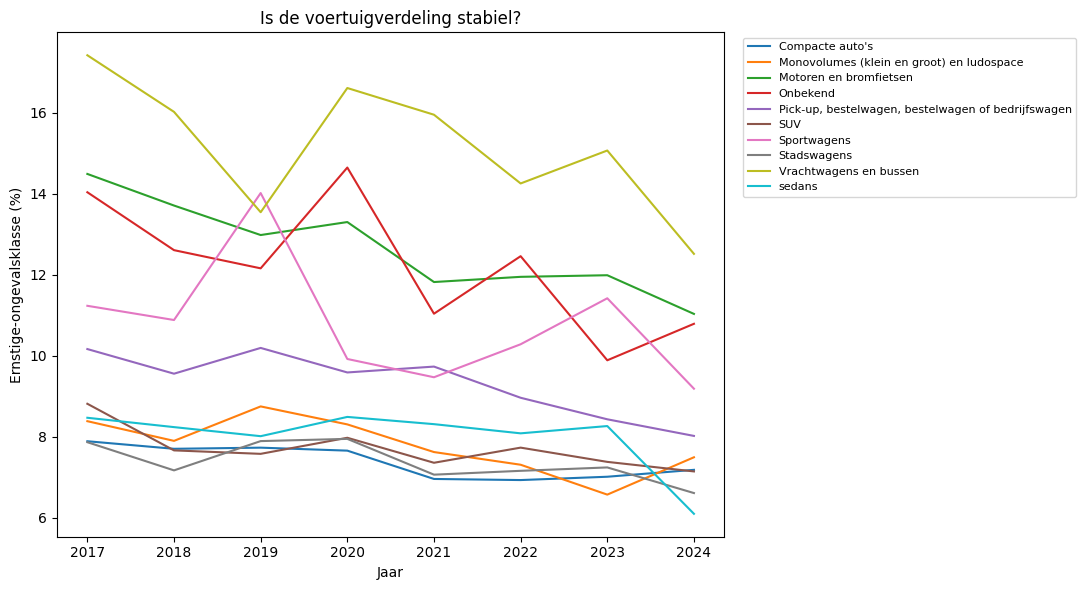

In [5]:
d=cars[cars.analysis_year.notna()].copy();d['ernstig']=d.CD_ACCIDENT_CLASS.isin(['1','2','4']);d['segment']=d.TX_VEHICLE_SEGMENT_B_NL.fillna('Onbekend')
t=d.groupby(['analysis_year','segment']).agg(n=('FL_VEHICLE','sum'),e=('ernstig','sum')).reset_index();t['pct']=100*t.e/t.n
pivot=t[t.segment.isin(veh.index)].pivot(index='analysis_year',columns='segment',values='pct');pivot.to_csv(T/'voertuigtype_ernst_trend.csv')
fig,ax=plt.subplots(figsize=(11,6));pivot.plot(ax=ax);ax.set(ylabel='Ernstige-ongevalsklasse (%)',xlabel='Jaar',title='Is de voertuigverdeling stabiel?');ax.legend(bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8);fig.tight_layout();fig.savefig(F/'14_voertuigtype_ernst_trend.png',dpi=200,bbox_inches='tight');fig.savefig(F/'14_voertuigtype_ernst_trend.svg',bbox_inches='tight');plt.show();plt.close(fig)


## Interpretatie voor de presentatie
Vergelijk de wegtypen met de meeste registraties met de wegtypen met het hoogste aandeel ernstig letsel. Als de rangorde wisselt, is dat de kern van de paradox: volume en ernst beantwoorden verschillende vragen. Voertuigpercentages zijn conditioneel op voertuigen die al in deze ongevallenbron voorkomen. Voor de vraag welk type auto de grootste **ongevalskans** heeft, zijn aantallen voertuigen of gereden kilometers per type nodig.

Een lijst van individuele straten is met deze bron niet betrouwbaar: de kaartdata heeft geen straatnaam en een automatische koppeling met de dichtstbijzijnde OSM-weg kan op kruispunten of parallelwegen misgaan. Gebruik de concentratiekaart uit notebook 01 om locaties te verkennen; valideer een wegkoppeling voordat een stratenranglijst wordt gepresenteerd.